## Initiation - directory and file selection and loading

In [1]:
# Mahdi colab
# %pip install pydicom SimpleITK nibabel

In [2]:
# Mahdi colab
# from google.colab import drive  # Imports the drive module from google.colab library.
#
# drive.mount('/content/drive')  # Mounts the Google Drive to the specified mount point '/content/drive'.
# hgucegxi_dir = r"/content/drive/MyDrive/VUB/Hospital Project/HGUCEGXI"  # Sets the variable `hgucegxi_dir` with the path to a specific directory within Google Drive.
# nifti_dir = r"/content/drive/MyDrive/VUB/Hospital Project/HGUCEGXI.nii"

In [3]:
# %%script false --no-raise-error

# Hossein local PC
hgucegxi_dir = r"Dataset\DICOMs\HGUCEGXI"
nifti_dir = r'Dataset\NIFTIs\HGUCEGXI.nii'

In [4]:
import os
import pydicom
import SimpleITK as sitk
import cv2
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib

In [5]:
# Uses the `os.listdir` function to retrieve a list of all files (and directories) contained in the `hgucegxi_dir` directory.
files = os.listdir(hgucegxi_dir)

# Slices the list `files` to retrieve the first five elements, which are the names of the first five files (or directories) in the specified directory.
files[:5]

['I1000000', 'I1000001', 'I1010000', 'I1020000', 'I1030000']

In [6]:
# from IPython.display import Image
# 
# fname = 'patient.gif'
# Image(open(fname, 'rb').read())  # local

In [7]:
from utilities import convert_to_nifti

# Calls the `convert_to_nifti` function with the source directory of DICOM files and the target path for the NIfTI file.
convert_to_nifti(hgucegxi_dir, nifti_dir)

# Reads a NIfTI image file located at the specified path using SimpleITK's ReadImage function.
# The file path is given as a raw string (noted by the 'r' prefix) to avoid the need for escaping backslashes.
# The resulting image is stored in the variable 'sitk_image'.
sitk_image = sitk.ReadImage(nifti_dir)

## visualization to insure correct loading of files

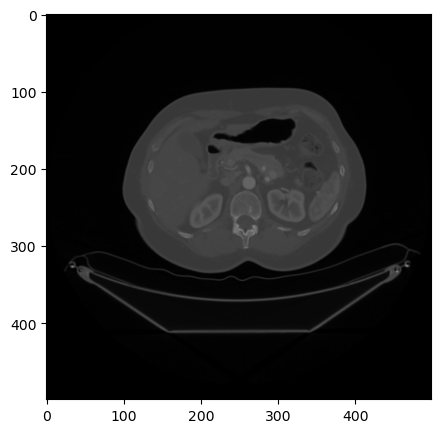

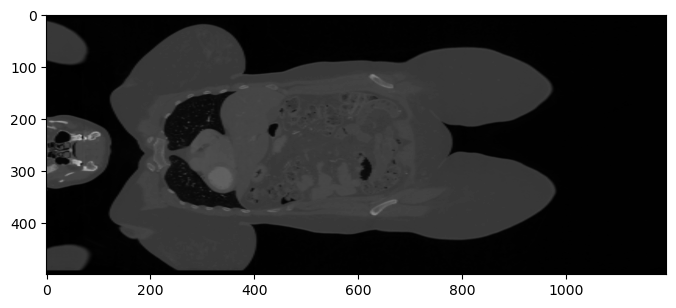

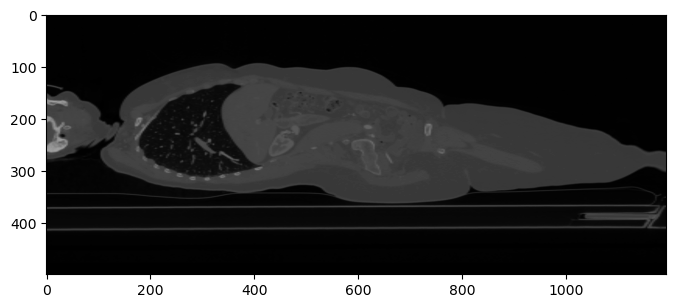

In [8]:
# Define a function to get orthogonal slices from a 3D image at specified indices.
def get_slices(image_3d, x, y, z):
    # Calculate the new spacing to maintain aspect ratio after resizing.
    # It multiplies the physical spacing with the shape of the image and converts to integer.
    spacing = (np.array(sitk_image.GetSpacing()[::-1]) * image_3d.shape[:3]).astype(int)

    # Extract and resize the axial slice at index x.
    x_img = cv2.resize(image_3d[x, :, :].astype(float), spacing[:0:-1])
    # Extract, resize, and rotate the sagittal slice at index y for proper orientation.
    y_img = cv2.rotate(cv2.resize(image_3d[:, y, :].astype(float), spacing[::-2]), cv2.ROTATE_90_CLOCKWISE)
    # Extract, resize, and rotate the coronal slice at index z for proper orientation.
    z_img = cv2.rotate(cv2.resize(image_3d[:, :, z].astype(float), spacing[:2][::-1]), cv2.ROTATE_90_CLOCKWISE)

    # Return the processed slices.
    return x_img, y_img, z_img


def show_slides(slides):
    # Visualize the axial slice.
    plt.figure(figsize=(8, 5))
    plt.imshow(slides[0], cmap='gray', vmin=-1024, vmax=3071)
    plt.show()

    # Visualize the sagittal slice.
    plt.figure(figsize=(8, 5))
    plt.imshow(slides[1], cmap='gray', vmin=-1024, vmax=3071)
    plt.show()

    # Visualize the coronal slice.
    plt.figure(figsize=(8, 8))
    plt.imshow(slides[2], cmap='gray', vmin=-1024, vmax=3071)
    plt.show()


# Convert the SimpleITK image to a NumPy array and get slices from it.
temp = get_slices(sitk.GetArrayFromImage(sitk_image), 250, 180, 215)
# Visualize the axial slice.
show_slides(temp)

# Seed Selection (visually)

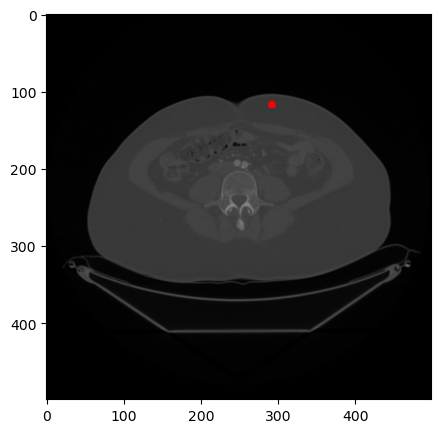

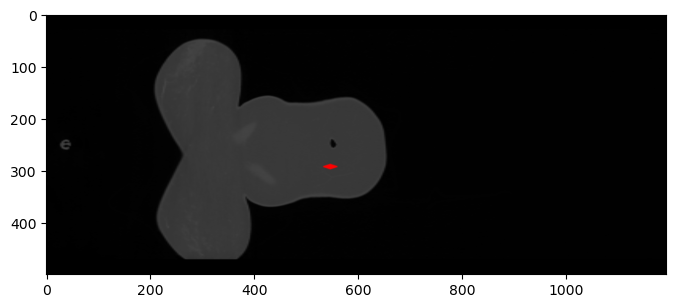

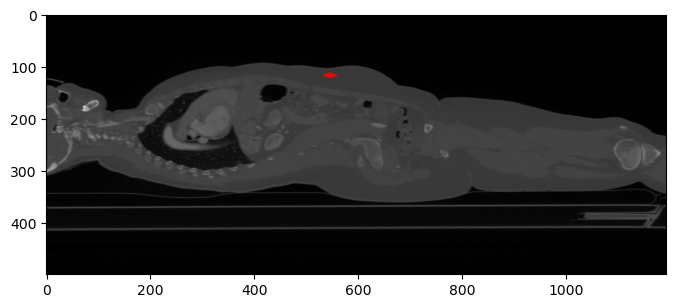

In [9]:
# Set a seed point for visualization
seed = (215, 120, 300)

# Convert the SimpleITK image to a NumPy array
temp = sitk.GetArrayFromImage(sitk_image)

# turn grayscale to rgb
temp = np.stack([temp, temp, temp], axis=-1)
temp = (temp - temp.min()) / (temp.max() - temp.min())

# place a dot at the seed location on the 3d image by going through each slides
for i in range(5):
    temp[seed[0] - i] = cv2.circle(temp[seed[0] - i], (seed[2], seed[1]), 5 - i, (1, 0, 0), -1)
    temp[seed[0] + i] = cv2.circle(temp[seed[0] + i], (seed[2], seed[1]), 5 - i, (1, 0, 0), -1)

temp = get_slices(temp, seed[0], seed[1], seed[2])
show_slides(temp)

## Fat Segmentation by using region growing
first narrow range of acceptable intensity change is considered, and then dilated. creating a "fat + area around fat" mask.
Then another region growing is done with a larger range, segmenting the fat and organs.
finally, the intersection of the two masks is considered as the fat mask.

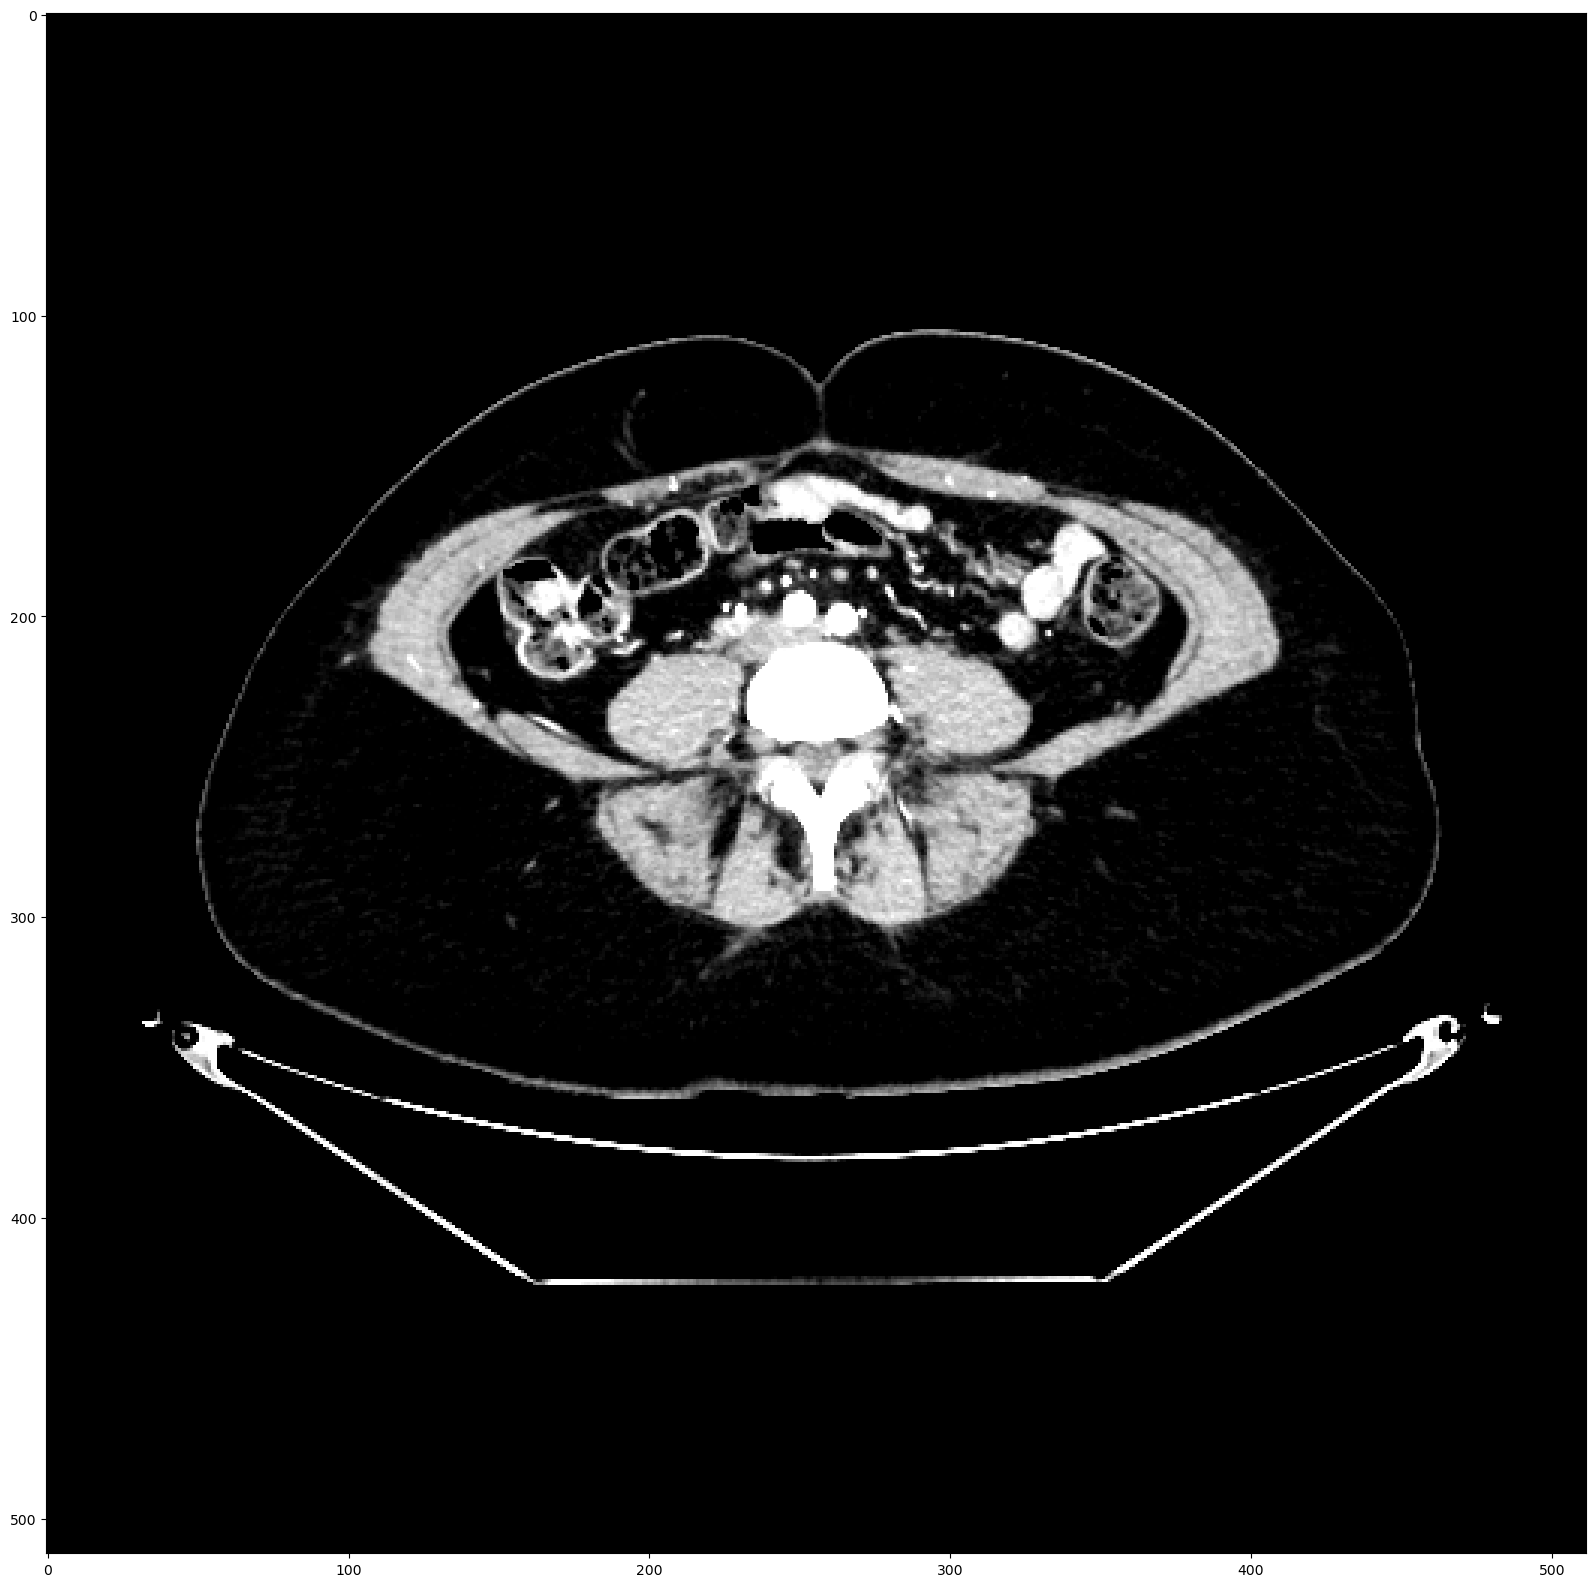

In [31]:
# Define a function to perform region growing segmentation on a SimpleITK image.
def get_region_grown(sitk_image, seed, r, dilation_steps=0):
    # Calculate the average intensity value of the voxel at the seed point and its immediate neighbors.
    # This considers the voxel itself and its neighbors in a 2x2x2 region.
    seed_value = np.mean([
        sitk.GetArrayFromImage(sitk_image)[seed[0] + i[0], seed[1] + i[1], seed[2] + i[2]]
        for i in [[0, 0, 0], [0, 0, 1], [0, 1, 0], [0, 1, 1], [1, 0, 0], [1, 0, 1], [1, 1, 0], [1, 1, 1]]
    ])

    # Perform the region growing segmentation based on the calculated average intensity value as the seed point.
    # `lower` and `upper` bounds for the segmentation are determined by subtracting and adding `r` to the seed value.
    seg_con = sitk.ConnectedThreshold(sitk_image, seedList=[seed], lower=seed_value - r, upper=seed_value + r)

    # Convert the resulting segmentation image back to a NumPy array.
    temp = sitk.GetArrayFromImage(seg_con)

    # The following lines, would apply morphological dilation to the segmented region.
    if dilation_steps != 0:
        temp = cv2.dilate(temp.astype(np.uint8), np.array([[0, 1, 0],
                                                           [1, 1, 1],
                                                           [0, 1, 0]]).astype(np.uint8),
                          iterations=dilation_steps)

    return temp

def fill_small_holes(mask, max_size):
    # Find all connected components in the mask.
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(1-mask.astype(np.uint8))

    # Iterate over the connected components.
    for i in range(1, num_labels):
        # If the area of the connected component is less than the specified maximum size, fill it.
        if stats[i, cv2.CC_STAT_AREA] < max_size:
            mask[labels == i] = 1

    return mask


def segment_fat(sitk_image, seed):
    # The first region growing for segmenting the fat and around.
    fat_and_around = get_region_grown(sitk_image, seed, 15, 3)
    # The second region growing for segmenting the fat and the organs.
    fat_and_organs = get_region_grown(sitk_image, seed, 45)
    # Combine the two masks.
    fat = fat_and_organs * fat_and_around

    # Fill the small areas around and in between.
    fat = [fill_small_holes(s, 100) for s in fat]
    fat = np.array(fat)

    return fat


sitk_image = sitk.ReadImage(nifti_dir)
plt.figure(figsize=(20, 20), dpi=100)
# Plot the original selected seed.
temp=sitk.GetArrayFromImage(sitk_image)[211]
temp=np.clip(temp, 0,100)/100 + np.clip(temp, -100,0)/100
plt.imshow(temp, cmap='gray')
# Apply the fat segmentation mask.
# fat_seg = segment_fat(sitk_image, seed)
# plt.imshow(fat_seg[seed[0]], alpha=fat_seg[seed[0]] * 0.4)

## compare the histogram of the image and the segmented fat
it intuitively seems that the range of the histogram for fat is exactly cut out of the histogram of the image

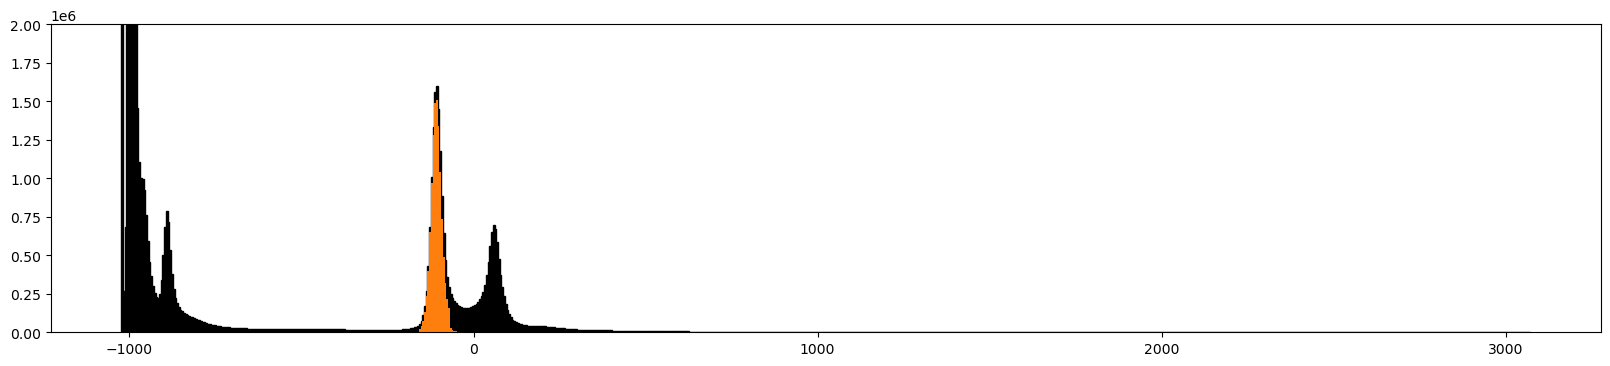

(-175.0, -50.0)

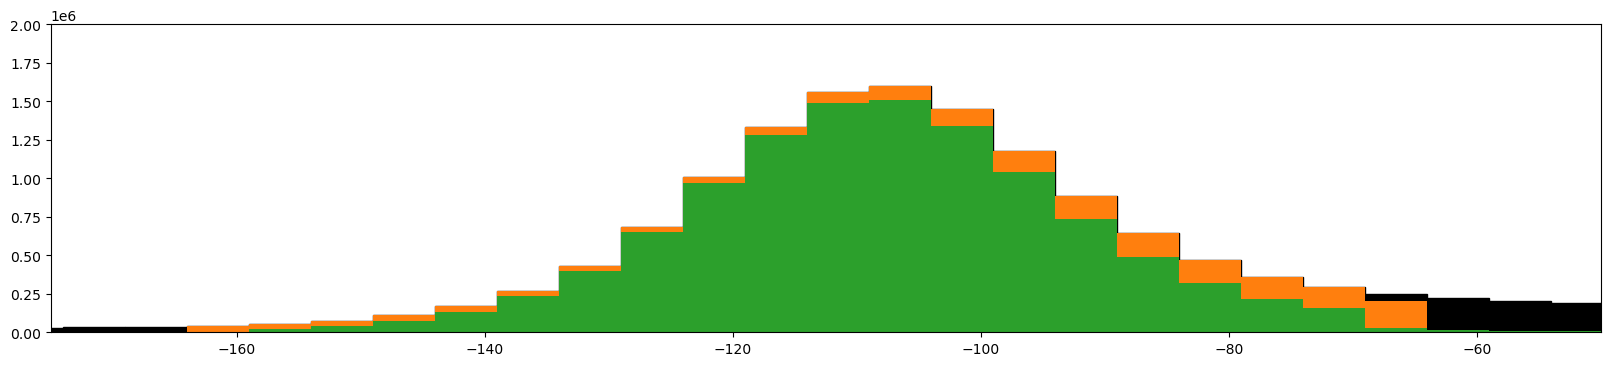

In [11]:
bin_size = 5
plt.figure(figsize=(20, 4))
temp = sitk.GetArrayFromImage(sitk_image)
plt.hist(temp.ravel(), bins=(1024 + 3071) // bin_size, range=(-1024, 3071), fc='k', ec='k')
temp = (temp + 100000) * fat_seg - 100000
plt.hist(temp.ravel(), bins=(1024 + 3071) // bin_size, range=(-1024, 3071))
plt.ylim(0, 2e6)
plt.show()

a_b_range = [-165, -65]
plt.figure(figsize=(20, 4))
temp = sitk.GetArrayFromImage(sitk_image)
plt.hist(temp.ravel(), bins=(1024 + 3071) // bin_size, range=(-1024, 3071), fc='k', ec='k')
temp2 = (temp > a_b_range[0]) & (temp < a_b_range[1])
temp = (temp + 100000) * temp2 - 100000
plt.hist(temp.ravel(), bins=(1024 + 3071) // bin_size, range=(-1024, 3071))
temp = sitk.GetArrayFromImage(sitk_image)
temp = (temp + 100000) * fat_seg - 100000
plt.hist(temp.ravel(), bins=(1024 + 3071) // bin_size, range=(-1024, 3071))
plt.ylim(0, 2e6)
plt.xlim(-175, -50)

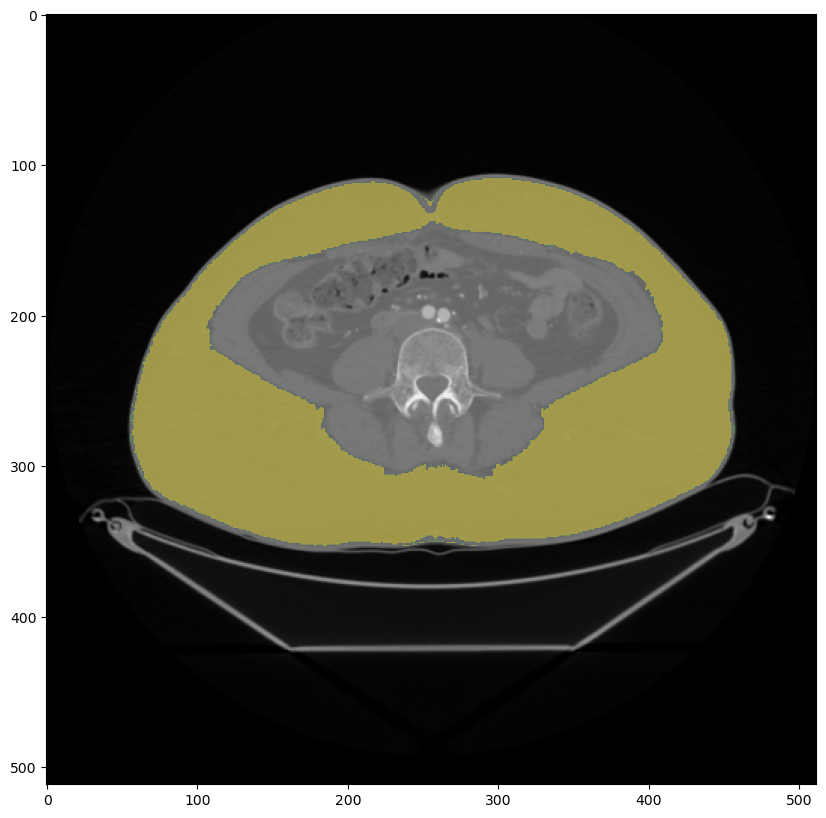

In [20]:
def segment_fat(sitk_image, seed, a_b_range = [-165, -65]):
    # The first region growing for segmenting the fat and around.
    fat_and_around = get_region_grown(sitk_image, seed, 15, 3)
    temp = sitk.GetArrayFromImage(sitk_image)
    # The second region growing for segmenting the fat and the organs (This time only with thresholding).
    fat_and_organs = (temp > a_b_range[0]) & (temp < a_b_range[1])

    fat_and_organs = [fill_small_holes(s, 10) for s in fat_and_organs]
    fat_and_organs = np.array(fat_and_organs)
    fat_and_organs = [fill_small_holes(s, 10) for s in fat_and_organs.transpose(1,2,0)]
    fat_and_organs = np.array(fat_and_organs).transpose(2,0,1)
    fat_and_organs = [fill_small_holes(s, 10) for s in fat_and_organs.transpose(2,0,1)]
    fat_and_organs = np.array(fat_and_organs).transpose(1,2,0)

    # Combine the two masks.
    fat = fat_and_organs * fat_and_around

    fat = sitk.ConnectedThreshold(sitk.GetImageFromArray(fat*100), seedList=[seed], lower=90, upper=110)
    fat = sitk.GetArrayFromImage(fat)

    # Fill the small areas around and in between.
    fat = [fill_small_holes(s, 40) for s in fat]
    fat = np.array(fat)

    return fat


sitk_image = sitk.ReadImage(nifti_dir)
plt.figure(figsize=(10, 10))
plt.imshow(sitk.GetArrayFromImage(sitk_image)[seed[0]], cmap='gray')
fat_seg2 = segment_fat(sitk_image, seed)
plt.imshow(fat_seg2[seed[0]], alpha=fat_seg2[seed[0]] * 0.4)

(-175.0, -50.0)

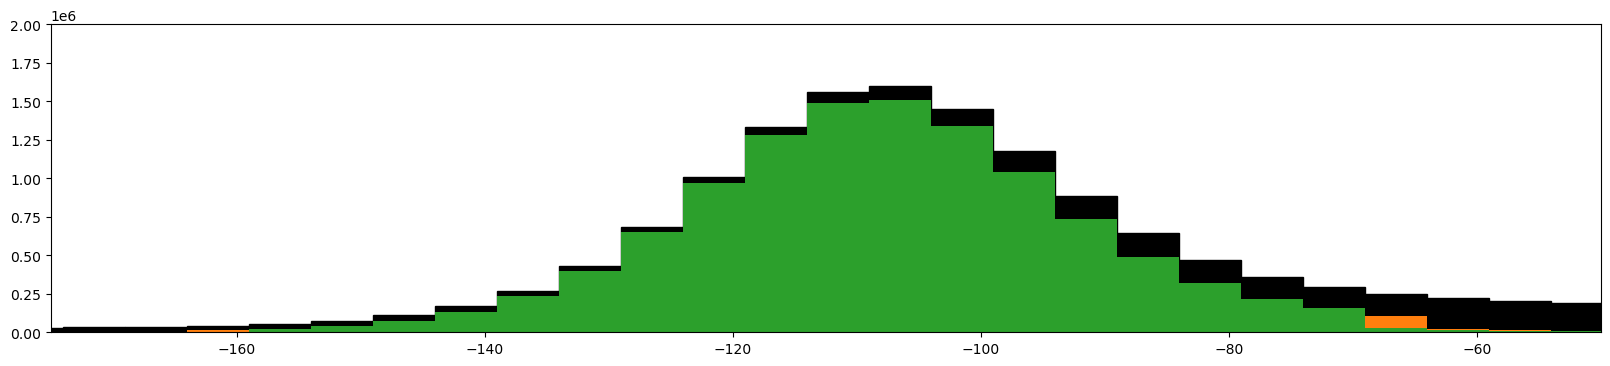

In [13]:
plt.figure(figsize=(20, 4))
temp = sitk.GetArrayFromImage(sitk_image)
plt.hist(temp.ravel(), bins=(1024 + 3071) // bin_size, range=(-1024, 3071), fc='k', ec='k')
temp2 = (temp + 100000) * fat_seg2 - 100000
plt.hist(temp2.ravel(), bins=(1024 + 3071) // bin_size, range=(-1024, 3071))
temp2 = (temp + 100000) * fat_seg - 100000
plt.hist(temp2.ravel(), bins=(1024 + 3071) // bin_size, range=(-1024, 3071))
plt.ylim(0, 2e6)
plt.xlim(-175, -50)

This approach is a robust technique to segment the fat region by combining region growing and HU thresholding.

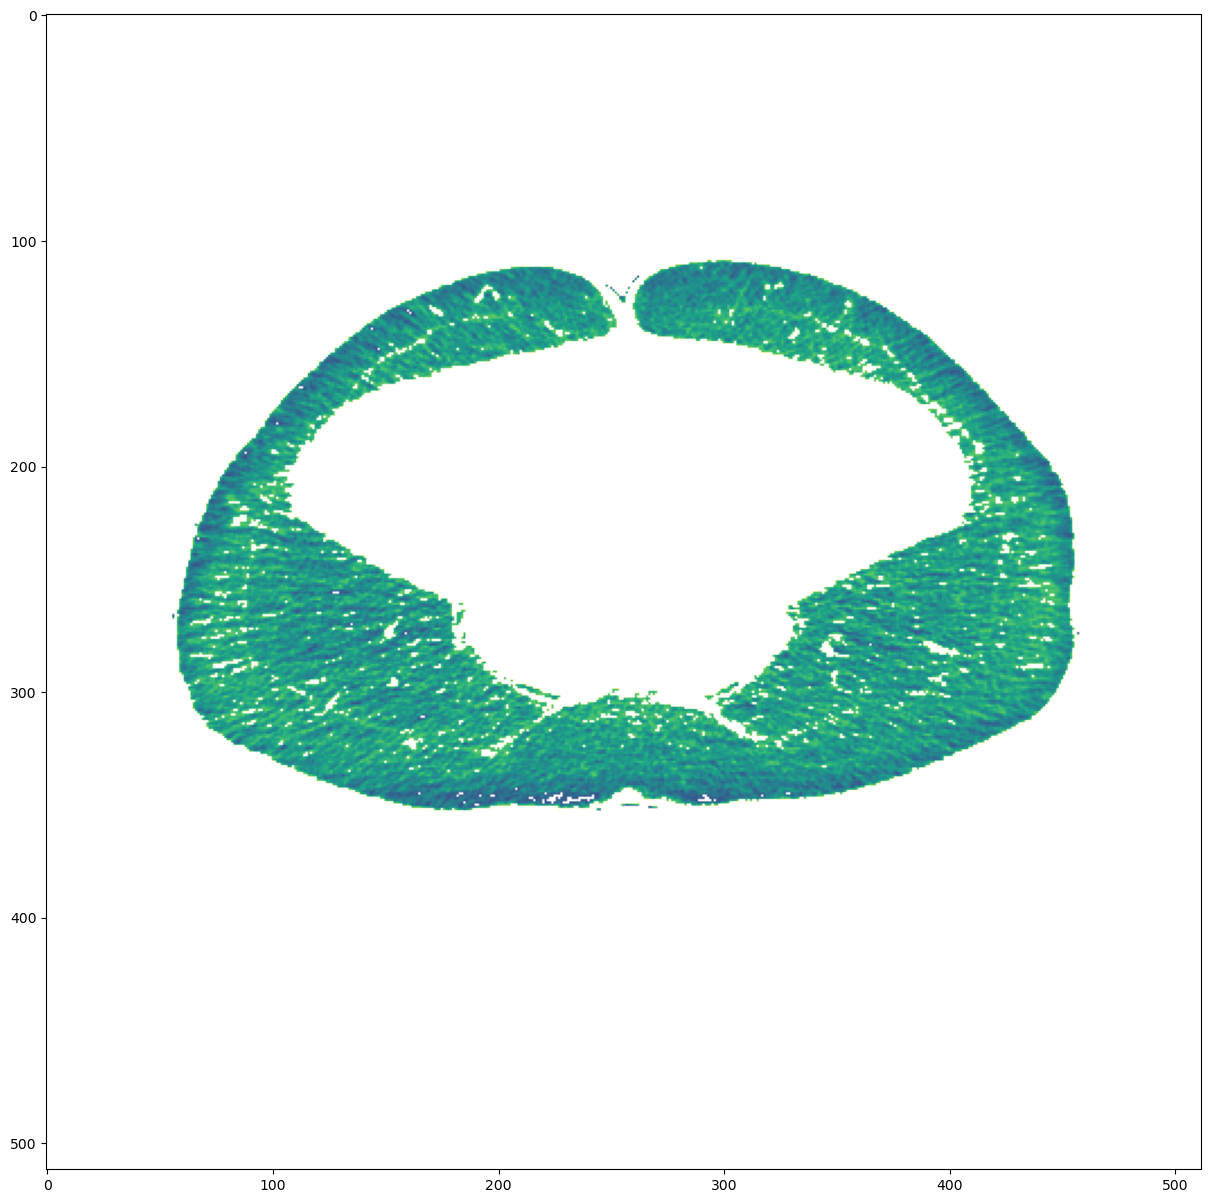

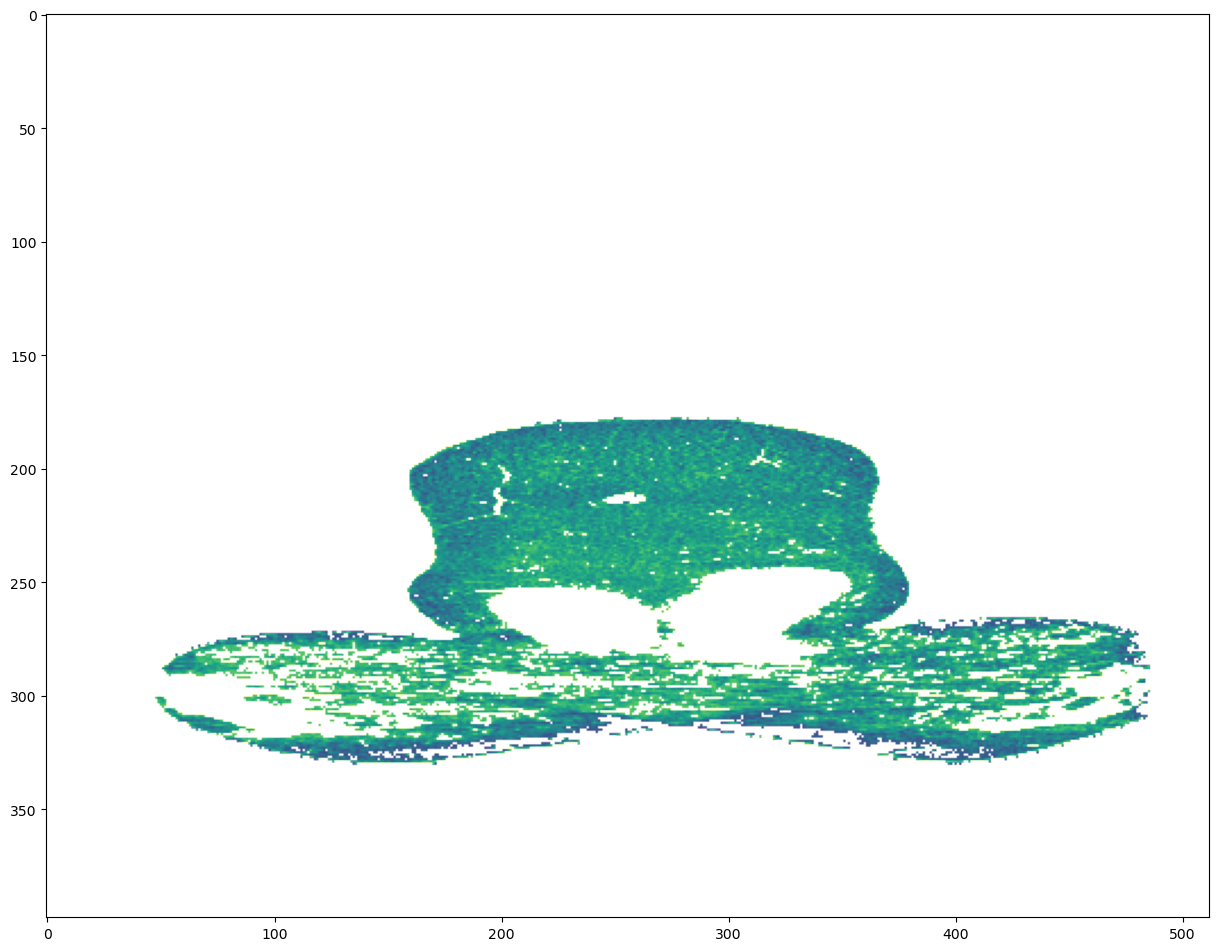

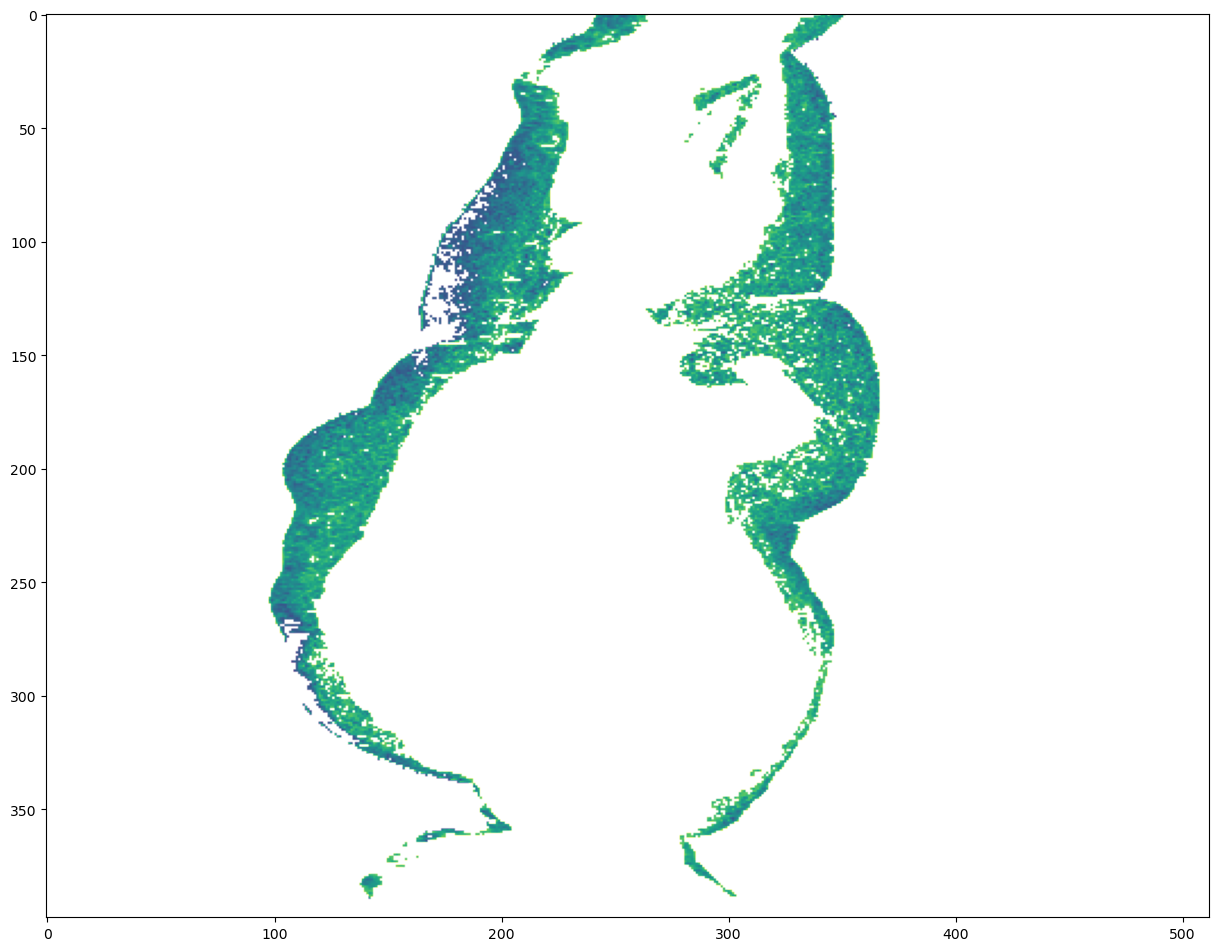

In [14]:
# Convert the SimpleITK image to a NumPy array.
img = sitk.GetArrayFromImage(sitk_image)
# Clip the pixel values of the image to be within the range determined by previously calculated percentiles (a, b).
img = np.clip(img, a_b_range[0], a_b_range[1])

# Get another NumPy array from the original SimpleITK image for processing.
temp = sitk.GetArrayFromImage(sitk_image)
# Create a mask based on whether pixel values are within the specified range (a, b).
# The result is a binary array where pixels within the range are set to 1, and others to 0.
temp = ((temp >= a_b_range[0]) & (temp <= a_b_range[1])).astype(float)
# Multiply the mask by the result of the region growing operation to highlight the region of interest.
# This effectively applies the mask to the segmented region, emphasizing the target area.
temp *= get_region_grown(sitk_image, seed, 25).astype(float)

# Visualize the axial slice at the seed's x-coordinate with the applied mask.
# The 'alpha' parameter controls the transparency, highlighting the region of interest.
plt.figure(figsize=(15, 15))
plt.imshow(img[seed[0], :, :], alpha=temp[seed[0], :, :])
plt.show()

# Visualize the sagittal slice, offset by 5 units from the seed's y-coordinate, with the mask.
plt.figure(figsize=(15, 15))
plt.imshow(img[:, seed[1] + 5, :], alpha=temp[:, seed[1] + 5, :])
plt.show()

# Visualize the coronal slice at the seed's z-coordinate with the mask.
plt.figure(figsize=(15, 15))
plt.imshow(img[:, :, seed[2]], alpha=temp[:, :, seed[2]])
plt.show()

# Vesselness Filter
Trying different filtering techniques to detect the vessels in the selected fat region.

In [14]:
from skimage.filters import frangi, sato, hessian

img = sitk.GetArrayFromImage(sitk_image)
# Interested slices in the abdominal region where the perforators exist.
img=img[200:220]
temp=img[fat_seg2[200:220].astype(bool)]
temp, temp2= temp.min(), temp.max()
img=np.clip(img, temp, temp2)
img = (img-np.min(img))/(np.max(img)-np.min(img))
img = img*fat_seg2[200:220]


frangi_slice = frangi(img)
sato_slice = sato(img)
hessian_slice = hessian(img)

def normlize(x):
    return (x - x.min()) / (x.max() - x.min())


# Use and test the combination of different filters.
vesselness_slice = (normlize(frangi_slice)*0 +
                    normlize(sato_slice) +
                    normlize(hessian_slice)*0)

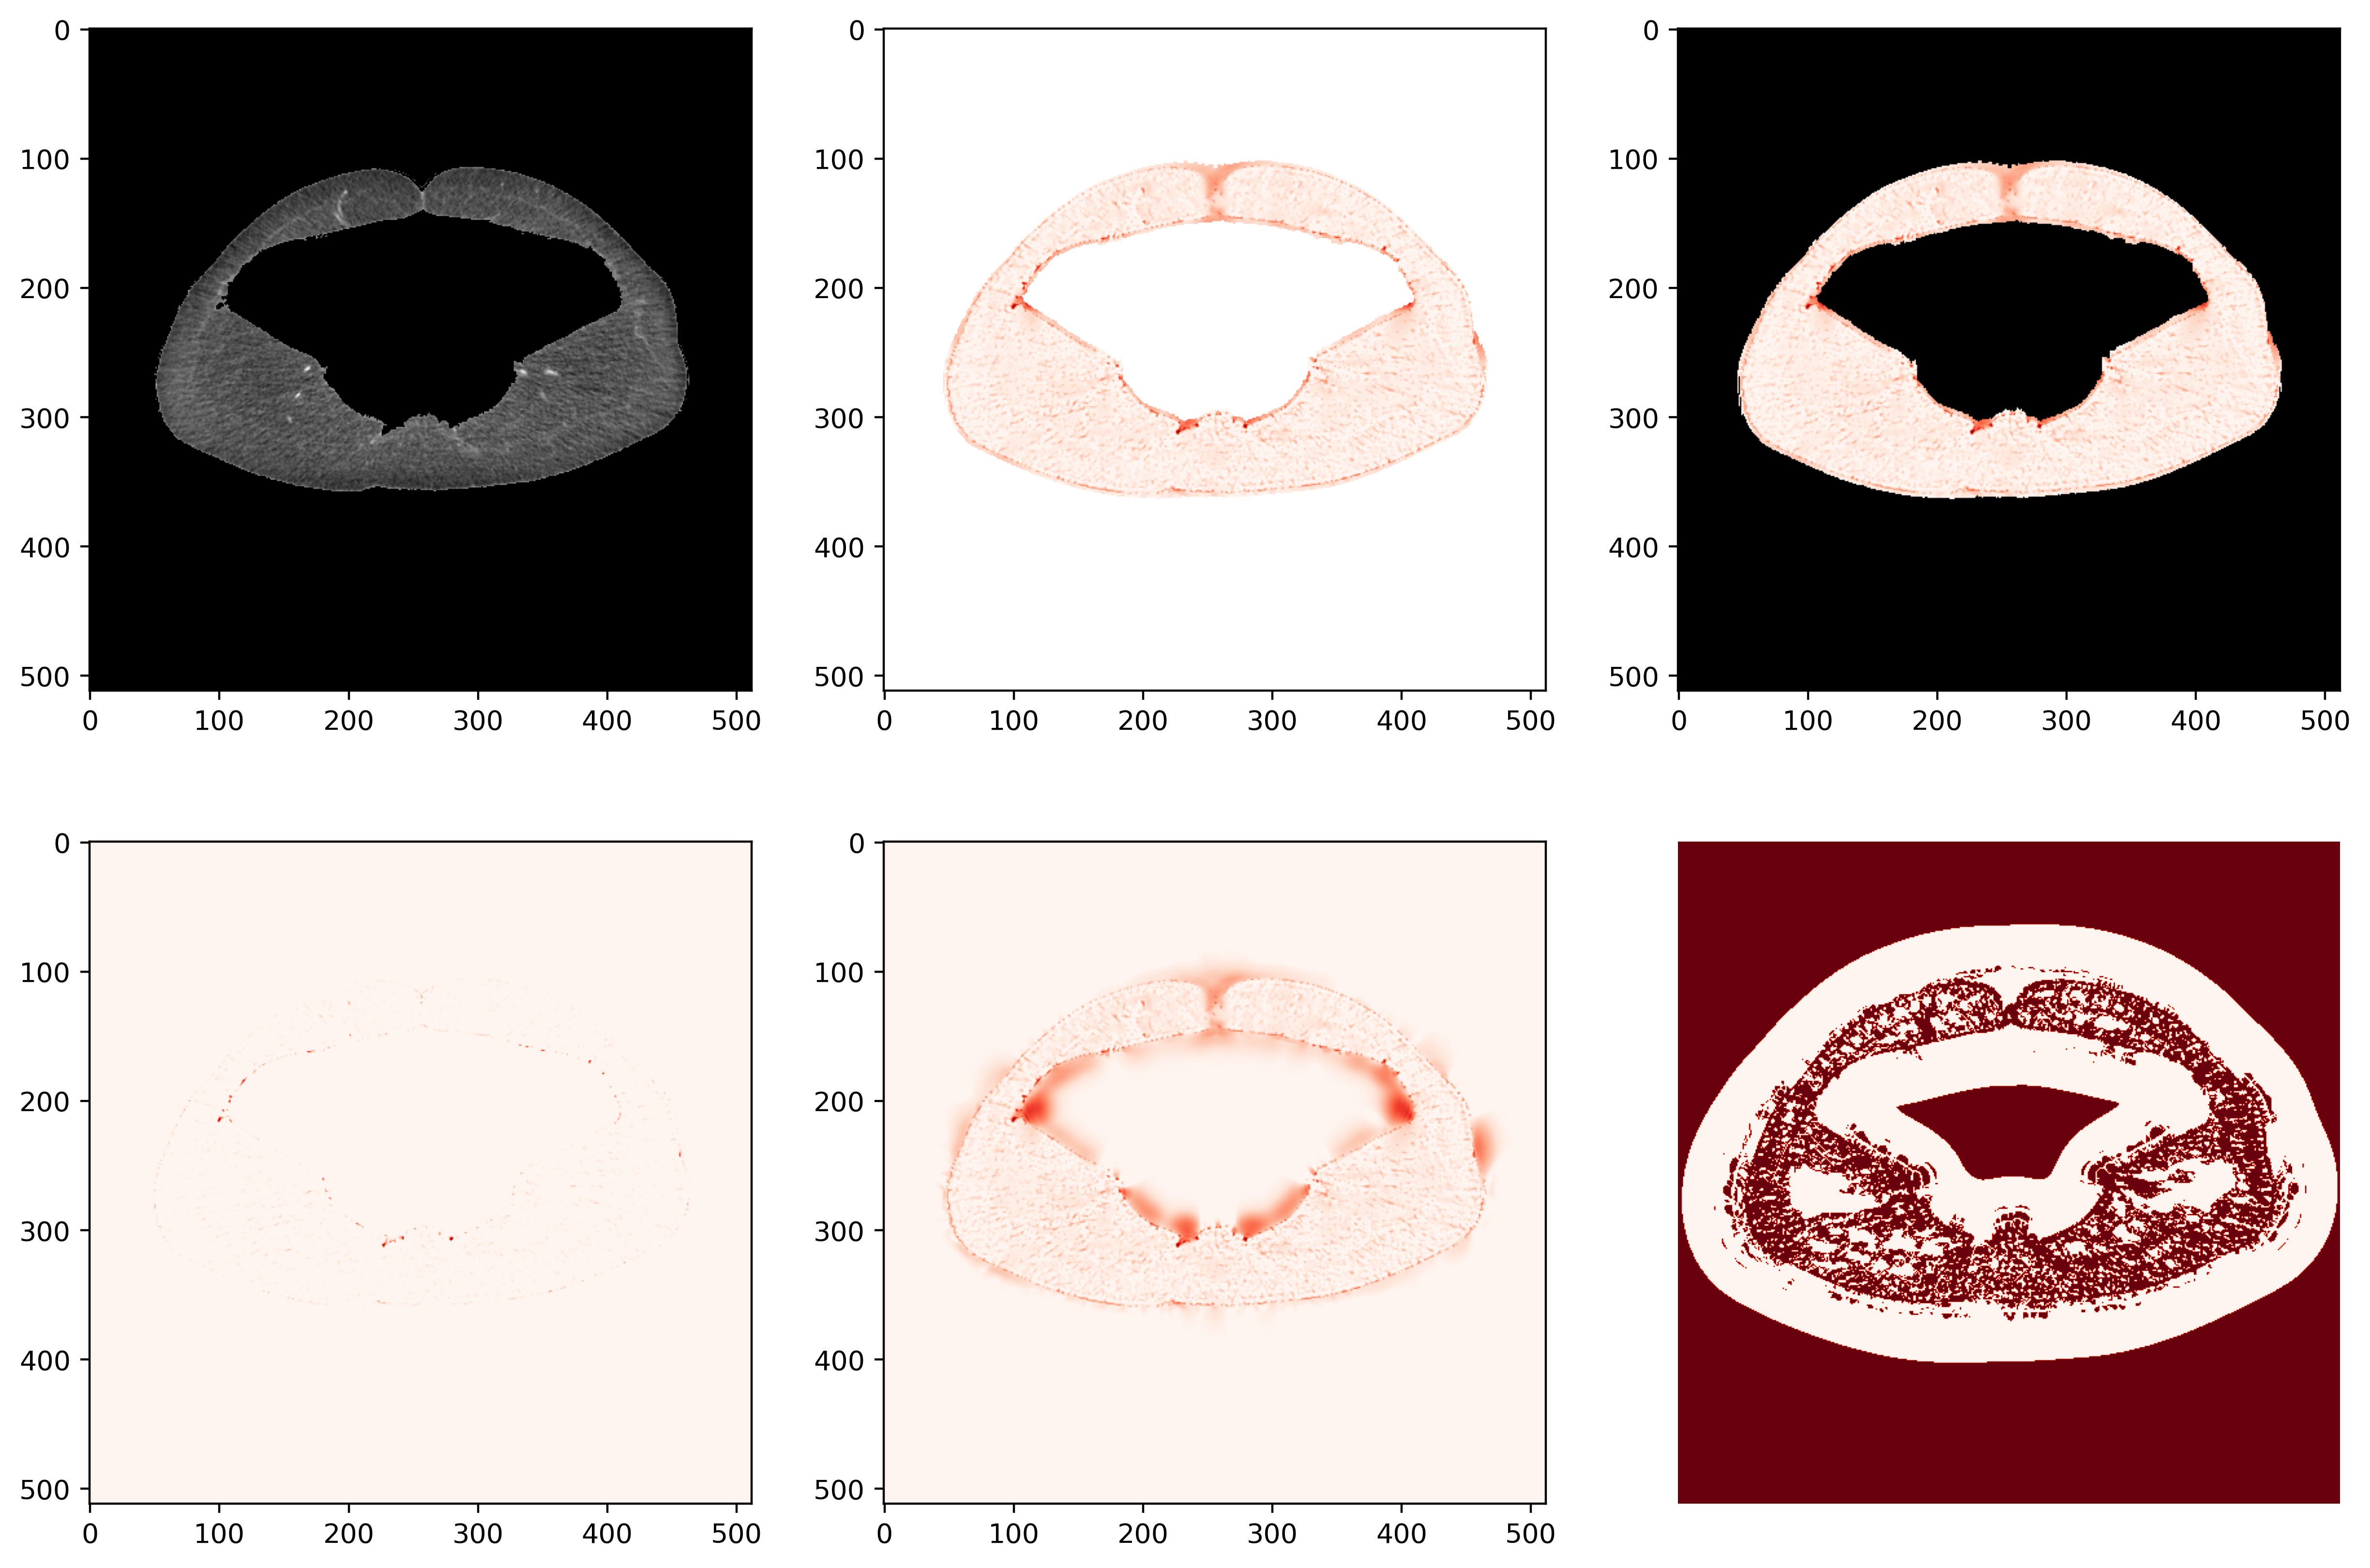

In [16]:
fig, ax = plt.subplots(2, 3, figsize=(15, 10),dpi=400)
# The plot at position 0,0 represents the original image of the slice 211
ax[0,0].imshow(img[11], cmap='gray')
ax[0,0].imshow(img[11]*0, cmap='gray', alpha=(1-fat_seg2[200:220][11])*0.5)

# The plot at position 0,1 represents the filter on the slice 211
temp=cv2.dilate(fat_seg2[200:220], np.ones((3,3)), iterations=3).astype(float)[11]
# ax[0,1].imshow(vesselness_slice[11], cmap='Reds', alpha=temp * 0.1)
ax[0,1].imshow(vesselness_slice[11], cmap='Reds', alpha=temp)


# The plot at position 0,2 represents the image of slice 211 after applying the filter.
ax[0,2].imshow(img[11], cmap='gray')
ax[0,2].imshow(vesselness_slice[11], cmap='Reds', alpha=temp)

# The plots at position 1,0 to 1,2 represent the mentioned filters on the slice 211
ax[1,0].imshow(frangi_slice[11], cmap='Reds')
ax[1,1].imshow(sato_slice[11], cmap='Reds')
ax[1,2].imshow(hessian_slice[11], cmap='Reds')

plt.axis('off')
plt.show()

In [18]:
from skimage import io, color, exposure, filters, morphology
from scipy.ndimage import distance_transform_edt
from skimage import data, measure, morphology, util

# Create a dictionary for hyper parameters
HP = {"slice_range": [200, 221], ## slice range fo the umbilical region
      "slice_nos": [11, 12, 19, 20], ## slice to visualize
      "height_crop": 4, ## Cropping the image based on height
      "frangi_scale_range": (1.5, 2),
      "frangi_scale_step": 0.2,
      "frangi_beta": 1,
      "frangi_gamma": 2,
      "vessel_size_threshold": 100  # Minimum number of pixels for a region to be kept
      }

def segment_fat_old(sitk_image, seed, a_b_range = [-165, -65]):
    # The first region growing for segmenting the fat and around.
    fat_and_around = get_region_grown(sitk_image, seed, 15, 3)
    temp = sitk.GetArrayFromImage(sitk_image)
    # The second region growing for segmenting the fat and the organs (This time only with thresholding).
    fat_and_organs = (temp > a_b_range[0]) & (temp < a_b_range[1])

    # Combine the two masks.
    fat = fat_and_organs * fat_and_around

    # Fill the small areas around and in between.
    fat = [fill_small_holes(s, 40) for s in fat]
    fat = np.array(fat)

    return fat

img = sitk.GetArrayFromImage(sitk_image)
# Interested slices in the abdominal region where the perforators exist.
img=img[HP["slice_range"][0]:HP["slice_range"][1]]
temp=img[fat_seg2[HP["slice_range"][0]:HP["slice_range"][1]].astype(bool)]
temp, temp2= temp.min(), temp.max()
img=np.clip(img, temp, temp2)
img = (img-np.min(img))/(np.max(img)-np.min(img))

fat_segment = segment_fat_old(sitk_image, seed, [-90, 20])
img = img*fat_segment[HP["slice_range"][0]:HP["slice_range"][1]]
cropped_image = img.copy()
plt.imshow(img[HP["slice_nos"][0]])
plt.show()

NameError: name 'fat_seg2' is not defined

C:\Users\hosse\AppData\Local\Temp\ipykernel_31388\1821421547.py:14: UserWarning: Use keyword parameter `sigmas` instead of `scale_range` and `scale_range` which will be removed in version 0.17.
  frangi_slice = frangi(


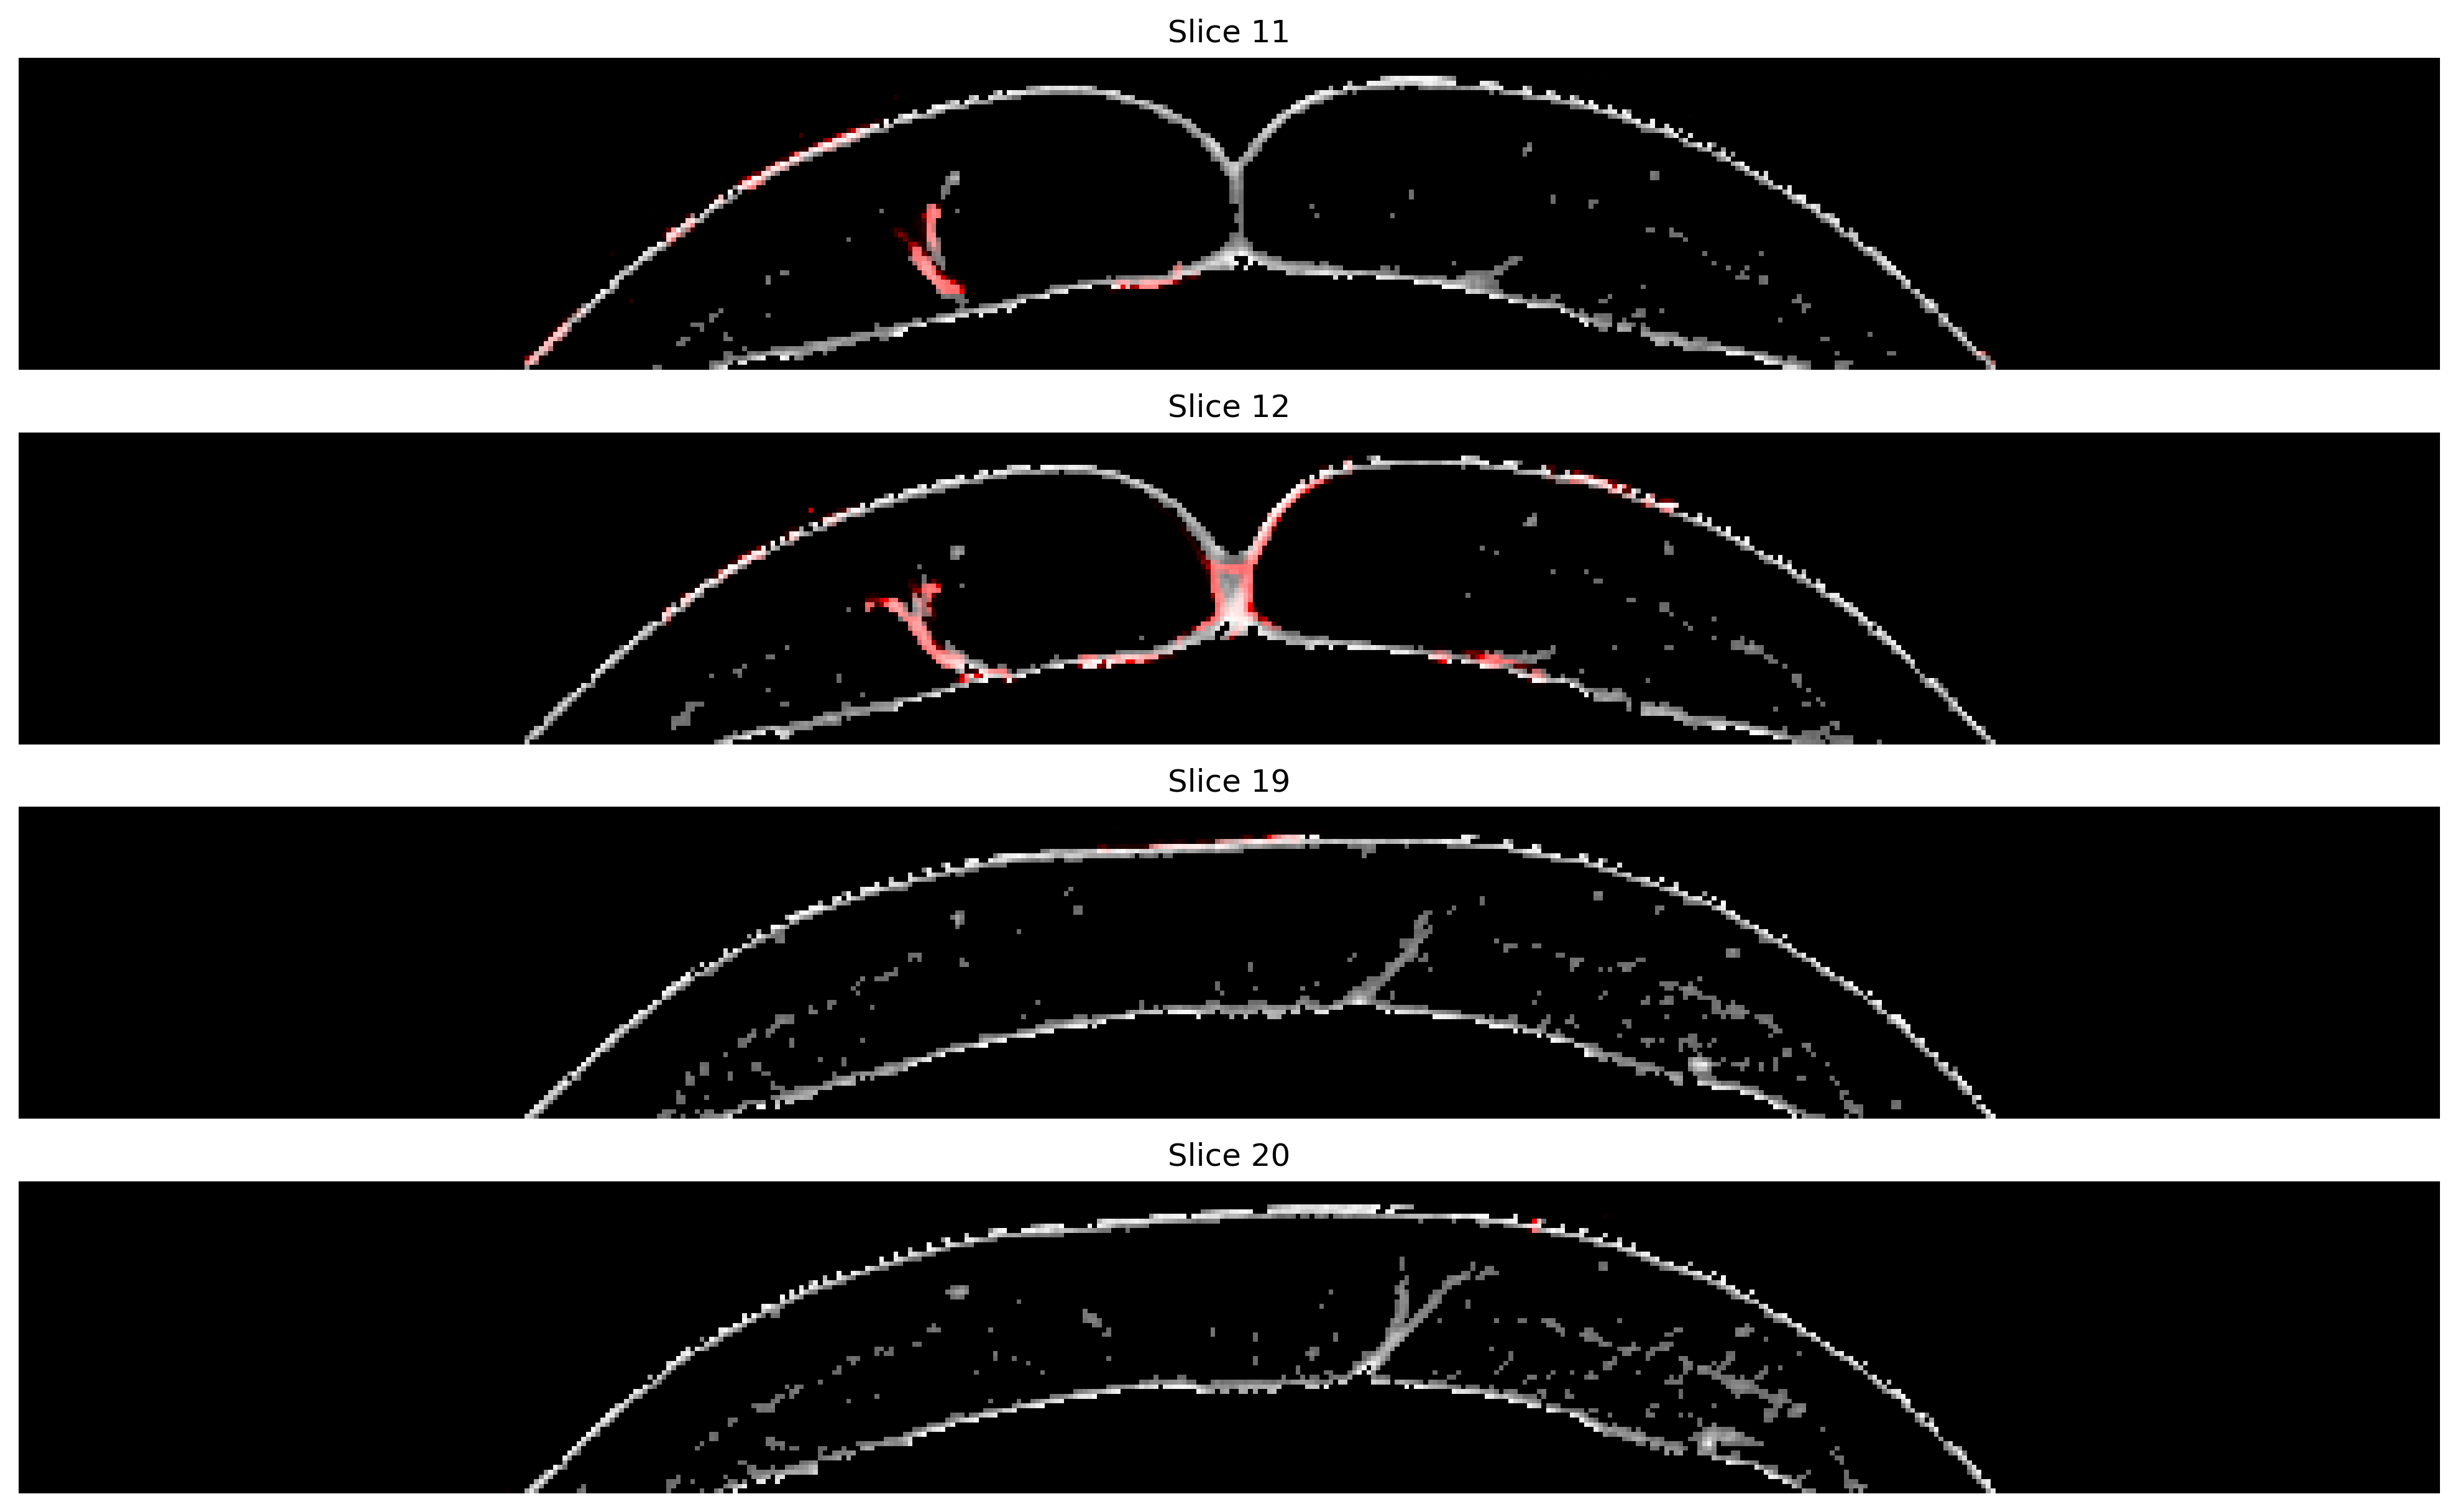

In [39]:
# Find the first and last y where there is a pixel that is not black
rows = np.any(cropped_image[0], axis=1)
first_y = np.argmax(rows)
last_y = len(rows) - np.argmax(rows[::-1])

# Crop the image to the first third in the y-dimension
cropped_image = cropped_image[:, first_y:last_y, :]
height = cropped_image.shape[1]
cropped_image = cropped_image[:, :height//HP["height_crop"], :]
## We first cropped the patient and then cropped the first 1/3 where the region of interest lies.


# Apply the Frangi filter with adjusted parameters
frangi_slice = frangi(
    cropped_image,
    scale_range=[HP["frangi_scale_range"][0], HP["frangi_scale_range"][1]],  # This range seems to be the size range of the vessel we have
    scale_step=HP["frangi_scale_step"],        # More fine-grained scale steps
    beta=HP["frangi_beta"],              # More sensitive to line-like structures
    gamma=HP["frangi_gamma"],               # Less background suppression for more sensitivity
    black_ridges=False     # Assuming bright ridges on dark background
)


fig, axes = plt.subplots(len(HP["slice_nos"]), 1, figsize=(15 * len(HP["slice_nos"]), 10), dpi=300)
for i, slice_no in enumerate(HP["slice_nos"]):
    cta_norm = exposure.rescale_intensity(cropped_image[slice_no], in_range='image', out_range=(0, 1))
    frangi_norm = exposure.rescale_intensity(frangi_slice[slice_no], in_range='image', out_range=(0, 1))

    # Label connected components based on continuous output
    # Utilizing a low threshold to ensure connectivity
    low_threshold = np.percentile(frangi_norm, 1)  # Keep 1% of the lowest values as background
    binary_image = frangi_norm > low_threshold
    label_image = measure.label(binary_image, connectivity=2)

    # Measure properties of labeled components
    properties = measure.regionprops(label_image, intensity_image=frangi_norm)


    # Create a mask to keep only large enough regions
    filtered_mask = np.zeros_like(frangi_norm, dtype=bool)
    for prop in properties:
        if prop.area >= HP["vessel_size_threshold"]:
            filtered_mask[label_image == prop.label] = True

    # Apply the mask to the original Frangi output (if needed)
    filtered_frangi = np.where(filtered_mask, frangi_norm, 0)

    # Create an empty color composite image
    composite_image = np.zeros((*cta_norm.shape, 3))

    composite_image[:, :, 0] = cta_norm  # Red channel
    composite_image[:, :, 1] = cta_norm  # Green channel
    composite_image[:, :, 2] = cta_norm  # Blue channel

    # Overlay the Frangi filter image to the red channel, adding it to existing red channel data
    composite_image[:, :, 0] += 5 * filtered_frangi  # Enhance the red channel with the Frangi filter

    # Clipping the red channel to ensure no overflow beyond 1
    composite_image[:, :, 0] = np.clip(composite_image[:, :, 0], 0, 1)

    # Display the composite image
    axes[i].imshow(composite_image)
    axes[i].axis('off')
    axes[i].set_title(f'Slice {slice_no}')

plt.show()

In [22]:
from skimage import io, color, exposure, filters, morphology
from scipy.ndimage import distance_transform_edt
from skimage import data, measure, morphology, util

# Create a dictionary for hyperparameters
HP = {"slice_range": [200, 225], ## slice range fo the umbilical region
      "vertical_slice_range": [100, 200], ## slice range fo the umbilical region
      
      "slice_no": [10,11,12, 18,19,20,21], ## slice to visualize
      
      "frangi_scale_range": (1, 2),
      "frangi_scale_step": 0.2,
      "frangi_beta": 1,
      "frangi_gamma": 4,
      
      "vessel_size_threshold": 200,  # Minimum number of pixels for a region to be kept
      "vertical_vessel_size_threshold": 50
      }

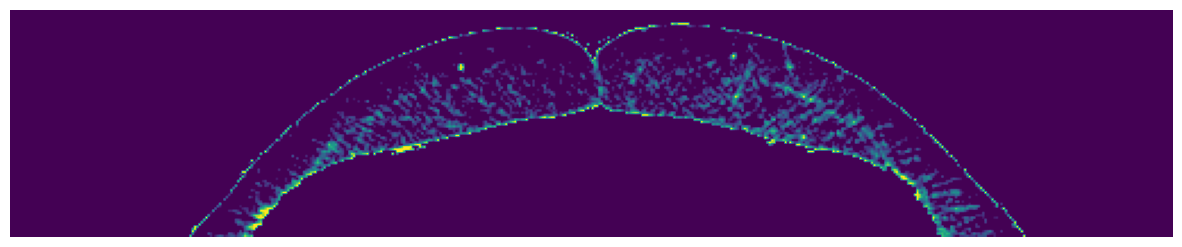

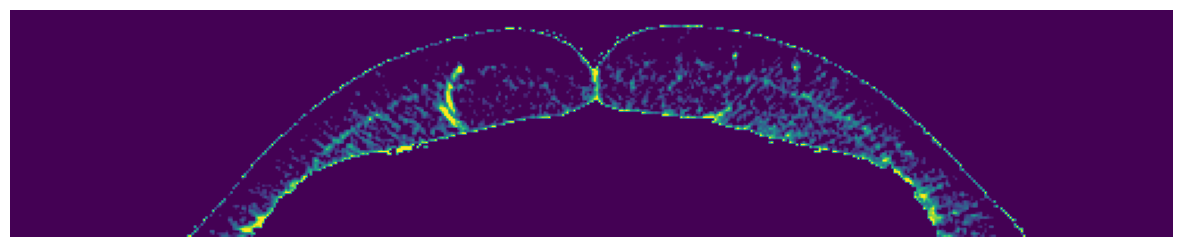

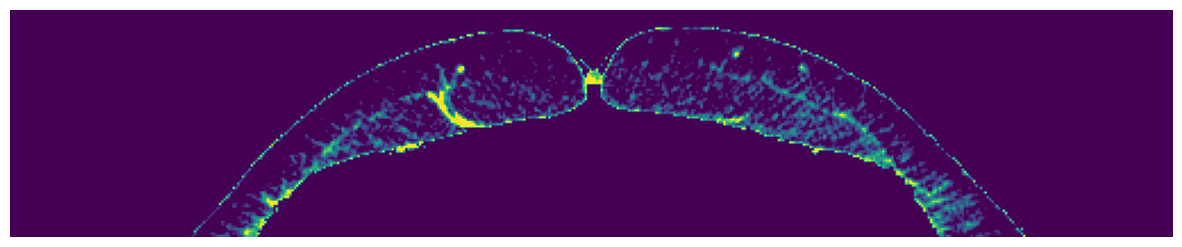

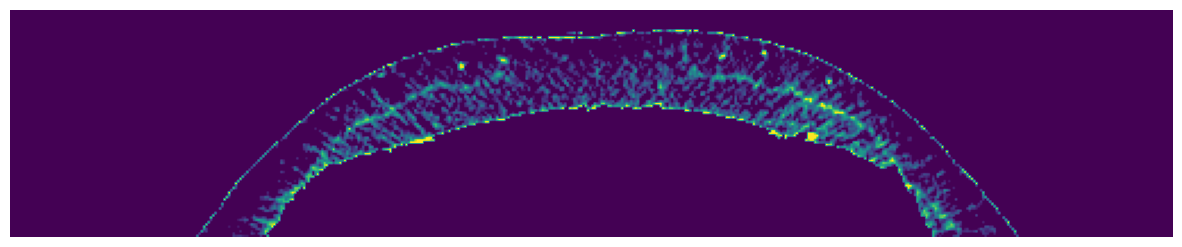

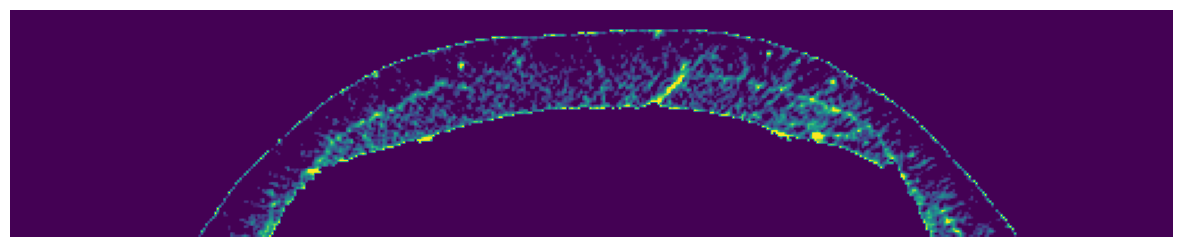

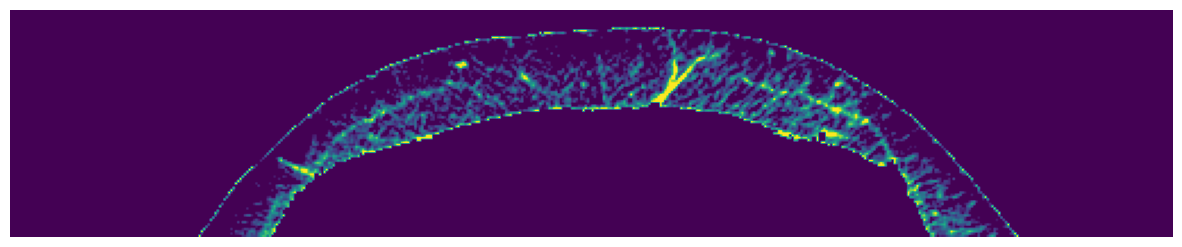

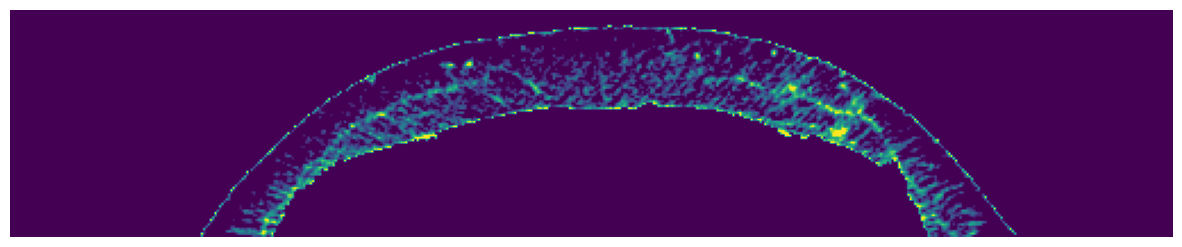

In [23]:
img = sitk.GetArrayFromImage(sitk_image)
fat_seg2 = segment_fat(sitk_image, seed, a_b_range = [-165, -65])
img = (img+10000)*fat_seg2-10000

temp=[slice(*HP["slice_range"]), slice(*HP["vertical_slice_range"])]
max_value, min_value, upper_gap_value, lower_gap_value = 98,60, 1,10
upper_gap_value, lower_gap_value = max_value+upper_gap_value, min_value-lower_gap_value
max_value, min_value, upper_gap_value, lower_gap_value = np.percentile(img[*temp][fat_seg2[*temp].astype(bool)], 
                                                                       [max_value, min_value, upper_gap_value, lower_gap_value])
img[img<min_value]=lower_gap_value
img[img>max_value]=upper_gap_value
img = (img - min_value) / (max_value - min_value)

cropped_image = img[*temp]

for i in HP["slice_no"]:
    plt.figure(figsize=(15, 10), dpi=100)
    plt.imshow(cropped_image[i])
    plt.axis('off')
    plt.show()

In [15]:
# Apply the Frangi filter with adjusted parameters
frangi_slice = frangi(
    cropped_image,
    scale_range=[HP["frangi_scale_range"][0], HP["frangi_scale_range"][1]],  # This range seems to be the size range of the vessel we have
    scale_step=HP["frangi_scale_step"],        # More fine-grained scale steps
    beta=HP["frangi_beta"],              # More sensitive to line-like structures
    gamma=HP["frangi_gamma"],               # Less background suppression for more sensitivity
    black_ridges=False     # Assuming bright ridges on dark background
)


NameError: name 'cropped_image' is not defined

In [93]:
from scipy.ndimage import label
filtered_frangi = frangi_slice.copy()
filtered_frangi = np.clip(filtered_frangi, *np.percentile(filtered_frangi[filtered_frangi>0], [0.1,99.9]))
filtered_frangi/=np.max(filtered_frangi)
filtered_frangi[filtered_frangi<0.1]=0
filtered_frangi = cv2.dilate(filtered_frangi.astype(float), np.ones((3,3,3)), iterations=1)

yolo=filtered_frangi.copy()

labeled_array, _ = label((filtered_frangi > 0), np.ones((3,3,3)))
for i in range(np.max(labeled_array)+1):
    labeled_pixels=labeled_array==i
    if np.sum(labeled_pixels) < 100:
        filtered_frangi[labeled_pixels]=0
#         continue
#         
#     slide_area = np.array([np.sum(labeled_pixels[i]) for i in range(labeled_pixels.shape[0])])
#     if (np.median(slide_area) + np.mean(slide_area))/2 < 50:
#         filtered_frangi[labeled_pixels]=0
#         continue
# 
#     for i, temp in enumerate(slide_area):
#         if temp<120:
#            filtered_frangi[i,labeled_pixels[i]]=0

yolo*=filtered_frangi==0
for i in HP["slice_no"]:
    plt.figure(figsize=(20, 10), dpi=100)
    plt.imshow(cropped_image[i], cmap="gray")
    plt.imshow(filtered_frangi[i], cmap='Reds', alpha=(filtered_frangi[i]>0).astype(float))
    plt.imshow(yolo[i], cmap='Greens', alpha=(yolo[i]>0).astype(float))
    plt.axis('off')
    plt.show()

error: OpenCV(4.9.0) D:\a\opencv-python\opencv-python\opencv\modules\core\src\count_non_zero.dispatch.cpp:124: error: (-215:Assertion failed) cn == 1 in function 'cv::countNonZero'
